## Dependencies

In [98]:
import sys
from pathlib import Path

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as patches
from PIL import Image
from torchvision import transforms
from matplotlib.ticker import MaxNLocator
from collections import Counter
from tqdm.auto import tqdm

# Make `src` importable when running from the notebooks/ folder
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Project imports
from src.utils.config_loader import load_config
from src.data.dataset import JointFractureDataset
from src.data.preprocessing import load_data_stats

## Global Variables

In [60]:
# ── Paths ──
DATA_ROOT = PROJECT_ROOT / "data" / "raw"
SPLITS = ["train", "val", "test"]
CLASS_NAMES = {0: "fractured", 1: "normal"}
FIG_DIR = PROJECT_ROOT / "results" / "figures" / "eda"

# ── Plot style ──
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# ── Image Extensions ──
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# —— PIL mode → (channels, bit_depth) ——
MODE_INFO = {
    "1":     (1, 1),
    "L":     (1, 8),
    "P":     (1, 8),   # palette
    "RGB":   (3, 8),
    "RGBA":  (4, 8),
    "CMYK":  (4, 8),
    "I":     (1, 32),
    "I;16":  (1, 16),
    "I;16B": (1, 16),
    "F":     (1, 32),
}

# —— Flags ——
OVERWRITE_FIGS = False   # set True to regenerate every figure on the next run

print(f"Project root: {PROJECT_ROOT}")
print(f"Data root:    {DATA_ROOT}")
print(f"Splits:       {SPLITS}")
print(f"Classes:      {CLASS_NAMES}")

Project root: c:\Users\Administrator\Desktop\SFU\Research Projects\joint-fracture
Data root:    c:\Users\Administrator\Desktop\SFU\Research Projects\joint-fracture\data\raw
Splits:       ['train', 'val', 'test']
Classes:      {0: 'fractured', 1: 'normal'}


## Prepare output folder <span style="color:red">(run once)</span>

In [ ]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Figures will be saved to: {FIG_DIR}")

Figures will be saved to: c:\Users\Administrator\Desktop\SFU\Research Projects\joint-fracture\results\figures\eda


## Functions Works as a Utilities

`save_fig` saves the current matplotlib figure to `FIG_DIR`, skipping it if the file already exists unless overwriting is turned on (globally via `OVERWRITE_FIGS` or per call via `overwrite=True`).

In [61]:
def save_fig(name, overwrite=None, **kwargs):
    """
    Save the current figure to FIG_DIR/name.

    overwrite=None  -> follow the global OVERWRITE_FIGS switch
    overwrite=True  -> always replace the existing file
    overwrite=False -> never replace the existing file
    """
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / name

    if overwrite is None:
        overwrite = OVERWRITE_FIGS

    if path.exists() and not overwrite:
        print(f"⏭️  Skipped (already exists): {path.name}  "
              f"(set OVERWRITE_FIGS = True or overwrite=True to replace)")
        return path

    action = "Overwrote" if path.exists() else "Saved"
    plt.savefig(path, dpi=150, bbox_inches="tight", **kwargs)
    print(f"💾 {action}: {path.name}")
    return path

`load_for_display` opens an image and returns it as an 8-bit grayscale NumPy array ready for matplotlib, rescaling 16-bit medical images to 0-255 and converting every other mode to grayscale.

In [68]:
def load_for_display(path):
    """
    Load an image from disk for matplotlib display.
    - Converts everything to grayscale (X-rays are grayscale anyway)
    - Handles RGB, L, I;16 (16-bit medical) uniformly
    """
    with Image.open(path) as im:
        # 16-bit → scale down to 8-bit for display
        if im.mode in ("I;16", "I;16B", "I"):
            arr = np.array(im, dtype=np.float32)
            arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8) * 255
            return arr.astype(np.uint8)
        # Everything else → grayscale 8-bit
        return np.array(im.convert("L"))

## Section 1 — Dataset Inventory & Image Properties

A complete walk of all splits produced a DataFrame of 1,906 images with 11 attributes per image (`path`, `split`, `class`, `width`, `height`, `aspect ratio`, `mode`, `channels`, `bit depth`, `file size`). Cross-validation against `JointFractureDataset` confirmed perfect count parity across all splits. Class imbalance was quantified per split — train `386:948` (1:2.46), consistent with val/test — motivating weighted sampling during training

In [48]:
records = []

for split in SPLITS:
    split_dir = DATA_ROOT / split
    if not split_dir.exists():
        print(f"⚠️  Missing folder: {split_dir}")
        continue
    for cls_id in [0, 1]:
        cls_dir = split_dir / str(cls_id)
        if not cls_dir.exists():
            continue
        for img_path in tqdm(sorted(cls_dir.iterdir()), desc=f"{split}/{cls_id}"):
            if img_path.suffix.lower() not in IMG_EXT:
                continue
            try:
                with Image.open(img_path) as im:
                    w, h = im.size
                    mode = im.mode
                    n_ch, bit_depth = MODE_INFO.get(mode, (None, None))
                    records.append({
                        "path":         img_path,
                        "filename":     img_path.name,
                        "split":        split,
                        "class_id":     cls_id,
                        "class_name":   CLASS_NAMES[cls_id],
                        "width":        w,
                        "height":       h,
                        "aspect_ratio": round(w / h, 4) if h else None,
                        "mode":         mode,
                        "channels":     n_ch,
                        "bit_depth":    bit_depth,
                        "file_size_kb": round(img_path.stat().st_size / 1024, 2),
                    })
            except Exception as e:
                print(f"❌ Failed to open {img_path}: {e}")

df = pd.DataFrame(records)
print(f"\n✅ DataFrame shape: {df.shape[0]} images × {df.shape[1]} columns")

test/1: 100%|██████████| 270/270 [00:00<00:00, 3822.10it/s]


✅ DataFrame shape: 1904 images × 12 columns


In [51]:
df = pd.DataFrame(records)
print(f"\n✅ DataFrame shape: {df.shape[0]} images × {df.shape[1]} columns")
print("—"*45)
df.sample(10)


✅ DataFrame shape: 1904 images × 12 columns
—————————————————————————————————————————————


,path,filename,split,class_id,class_name,width,height,aspect_ratio,mode,channels,bit_depth,file_size_kb
385,c:\Users\Administrator\Desktop\SFU\Research Pr...,IM (99).jpg,train,0,fractured,224,224,1.0,RGB,3,8,7.89
212,c:\Users\Administrator\Desktop\SFU\Research Pr...,IM (375).jpg,train,0,fractured,224,224,1.0,RGB,3,8,9.21
1294,c:\Users\Administrator\Desktop\SFU\Research Pr...,IM (951).jpg,train,1,normal,224,224,1.0,RGB,3,8,9.30
1448,c:\Users\Administrator\Desktop\SFU\Research Pr...,IM (272).jpg,val,1,normal,224,224,1.0,RGB,3,8,8.28
1900,c:\Users\Administrator\Desktop\SFU\Research Pr...,IM (989).jpg,test,1,normal,224,224,1.0,RGB,3,8,10.27
1859,c:\Users\Administrator\Desktop\SFU\Research Pr...,IM (894).jpg,test,1,normal,224,224,1.0,RGB,3,8,10.05
1831,c:\Users\Administrator\Desktop\SFU\Research Pr...,IM (830).jpg,test,1,normal,224,224,1.0,RGB,3,8,8.50
1591,c:\Users\Administrator\Desktop\SFU\Research Pr...,IM (27).jpg,test,0,fractured,224,224,1.0,RGB,3,8,8.45
50,c:\Users\Administrator\Desktop\SFU\Research Pr...,IM (166).jpg,train,0,fractured,224,224,1.0,RGB,3,8,9.47
556,c:\Users\Administrator\Desktop\SFU\Research Pr...,IM (1201).jpg,train,1,normal,224,224,1.0,RGB,3,8,10.67


### 1. Counts table (split × class)

In [32]:
counts_table = (
    df.groupby(["split", "class_name"])
      .size()
      .unstack(fill_value=0)
      .reindex(index=SPLITS, columns=["fractured", "normal"], fill_value=0)
)
counts_table["total"] = counts_table.sum(axis=1)
print("──────── Counts per split × class ────────")
print(counts_table)
print()

──────── Counts per split × class ────────
class_name  fractured  normal  total
split                               
train             386     948   1334
val                55     135    190
test              110     270    380



### 2. Cross-check with JointFractureDataset

In [ ]:
print("── Cross-check: JointFractureDataset vs raw walk ──")
for split in SPLITS:
    raw_count = len(df[df.split == split])
    try:
        ds = JointFractureDataset(root=DATA_ROOT / split)
        ds_count = len(ds)
        status = "✅" if raw_count == ds_count else "❌ MISMATCH"
        print(f"  {split:5s}: raw={raw_count:4d}  dataset={ds_count:4d}  {status}")
    except FileNotFoundError as e:
        print(f"  {split:5s}: raw={raw_count:4d}  dataset=SKIPPED ({e})")
print()

── Cross-check: JointFractureDataset vs raw walk ──
  train: raw=1334  dataset=1334  ✅
  val  : raw= 190  dataset= 190  ✅
  test : raw= 380  dataset= 380  ✅



### 3. Imbalance ratio per split

In [ ]:
print("───────── Class imbalance ratio (fractured : normal) ─────────")
for split in SPLITS:
    row = counts_table.loc[split]
    frac, norm = row["fractured"], row["normal"]
    if norm > 0:
        ratio = frac / norm
        print(f"  {split:5s}: {frac:4d} : {norm:4d}  (ratio = 1 : {norm/frac:.2f}  →  fractured = {100*frac/(frac+norm):.1f}%)")
    else:
        print(f"  {split:5s}: {frac} : 0  (no normal class!)")


───────── Class imbalance ratio (fractured : normal) ─────────
  train:  386 :  948  (ratio = 1 : 2.46  →  fractured = 28.9%)
  val  :   55 :  135  (ratio = 1 : 2.45  →  fractured = 28.9%)
  test :  110 :  270  (ratio = 1 : 2.45  →  fractured = 28.9%)


### 4. Image dimensions — are they all the same?

In [53]:
print("── Image dimensions per split ──")
dim_summary = (
    df.groupby("split")[["width", "height"]].agg(["min", "median", "max"])
)
print(dim_summary)

── Image dimensions per split ──
      width             height            
        min median  max    min median  max
split                                     
test    224  224.0  224    224  224.0  224
train   203  224.0  224    224  224.0  224
val     224  224.0  224    224  224.0  224


### 5. Unique (width, height) clusters

In [54]:
print("── Unique (width, height) pairs ──")
dims = df.groupby(["width", "height"]).size().reset_index(name="count").sort_values("count", ascending=False)
print(dims.to_string(index=False))

── Unique (width, height) pairs ──
 width  height  count
   224     224   1902
   203     224      1
   213     224      1


### 6. Mode / channels / bit-depth distribution

In [57]:
print("── Image mode distribution ──")
mode_summary = df.groupby(["mode", "channels", "bit_depth"]).size().reset_index(name="count")
print(mode_summary.to_string(index=False))

── Image mode distribution ──
mode  channels  bit_depth  count
 RGB         3          8   1904


### 7. File size per split

In [58]:
print("── File size (KB) per split ──")
size_summary = (
    df.groupby("split")["file_size_kb"]
      .agg(min="min", median="median", mean="mean", max="max")
      .round(2)
)
print(size_summary)

── File size (KB) per split ──
        min  median  mean    max
split                           
test   6.06    9.24  9.34  12.45
train  5.51    9.20  9.29  12.45
val    7.38    9.00  9.13  11.84


## Section 2 — Class Distribution & Imbalance Analysis

Bar, pie, and stacked-ratio plots were generated to visualize dataset balance. The overall split is 29% fractured / 71% normal, a moderate-to-high imbalance (2.5:1) that requires class-aware training. Imbalance was shown to be consistent across train/val/test, indicating a well-stratified split. All figures were saved to `results/figures/eda/*`.

### 1. Class counts (bar) + overall split (pie)

💾 Saved: 01_class_distribution.png


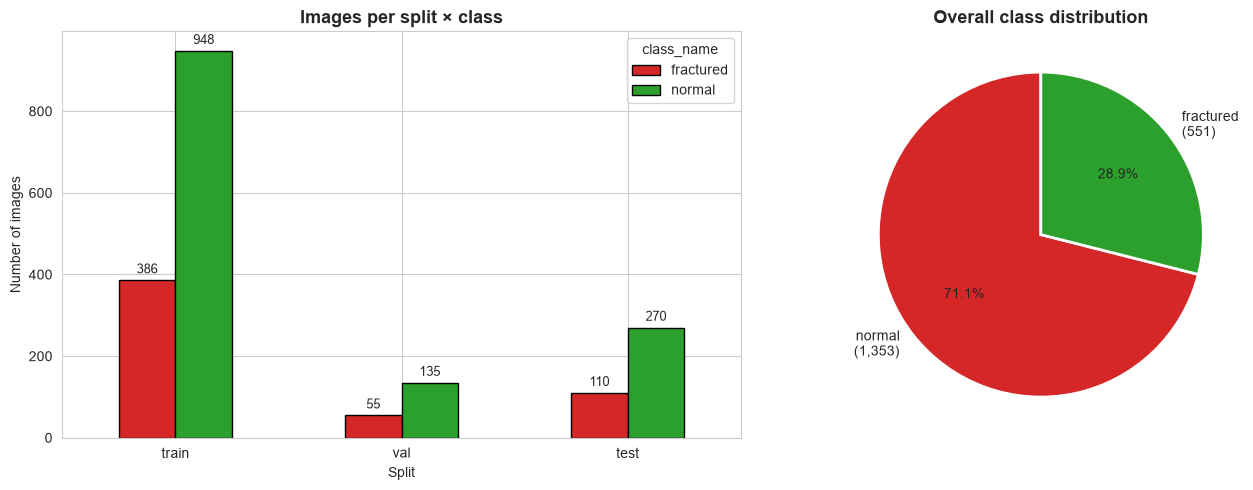

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: grouped bar chart — split × class
counts_table[["fractured", "normal"]].plot(
    kind="bar", ax=axes[0], color=["#d62728", "#2ca02c"], edgecolor="black"
)
axes[0].set_title("Images per split × class", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Number of images")
axes[0].tick_params(axis="x", rotation=0)
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3, fontsize=9)

# Right: pie chart — overall class ratio
overall = df["class_name"].value_counts()
axes[1].pie(
    overall.values,
    labels=[f"{k}\n({v:,})" for k, v in overall.items()],
    autopct="%1.1f%%",
    colors=["#d62728", "#2ca02c"],
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)
axes[1].set_title("Overall class distribution", fontsize=13, fontweight="bold")

plt.tight_layout()
save_fig(FIG_DIR / "01_class_distribution.png")     # Want to overwrite? just put overwrite=True
plt.show()

### 2. Class ratio per split (normalized to 100%)

💾 Saved: 02_class_ratio_per_split.png


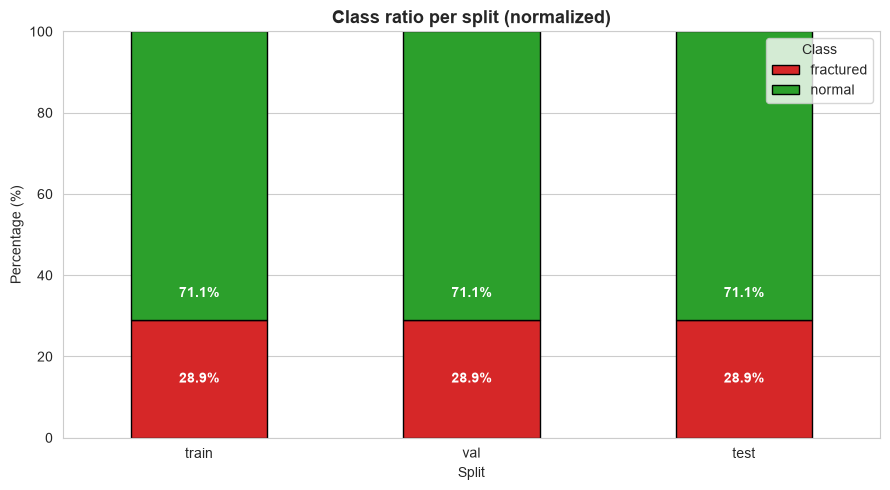

In [ ]:
ratio_table = counts_table[["fractured", "normal"]].div(
    counts_table[["fractured", "normal"]].sum(axis=1), axis=0
) * 100

fig, ax = plt.subplots(figsize=(9, 5))
ratio_table.plot(
    kind="bar", stacked=True, ax=ax,
    color=["#d62728", "#2ca02c"], edgecolor="black"
)
ax.set_title("Class ratio per split (normalized)", fontsize=13, fontweight="bold")
ax.set_xlabel("Split")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper right", title="Class")
for split_idx, (_, row) in enumerate(ratio_table.iterrows()):
    cum = 0
    for cls, val in row.items():
        if val > 0:
            ax.text(split_idx, cum + val / 2, f"{val:.1f}%",
                    ha="center", va="center", color="white", fontweight="bold")

plt.tight_layout()
save_fig(FIG_DIR / "02_class_ratio_per_split.png")
plt.show()

### 3. File size distribution per class

💾 Saved: 03_file_size_per_class.png


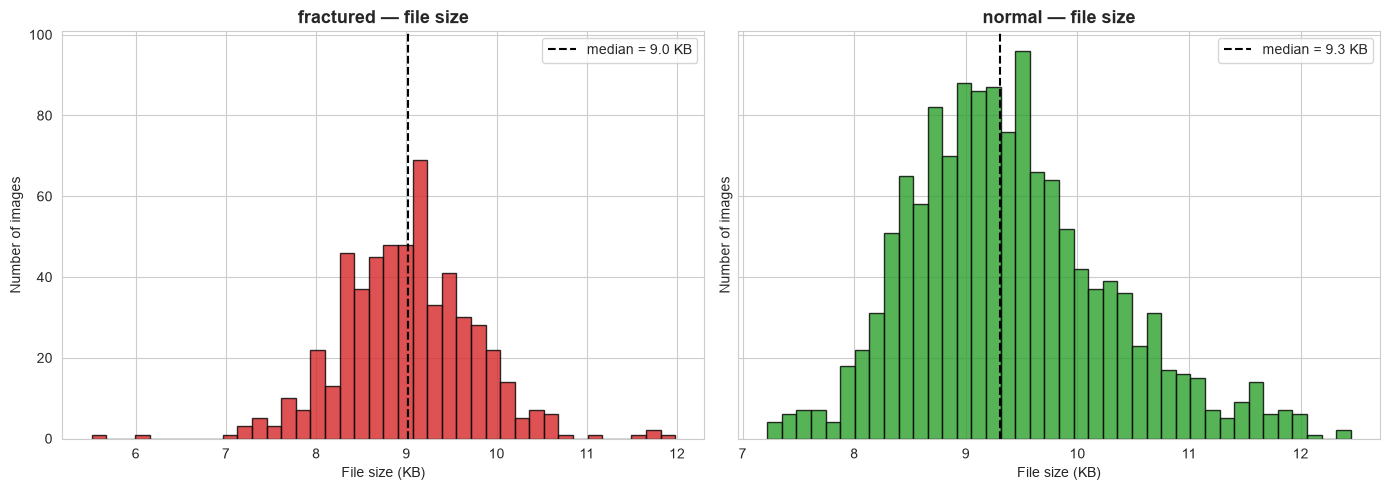

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, cls in zip(axes, ["fractured", "normal"]):
    data = df.loc[df.class_name == cls, "file_size_kb"]
    ax.hist(data, bins=40, color="#d62728" if cls == "fractured" else "#2ca02c",
            edgecolor="black", alpha=0.8)
    ax.axvline(data.median(), color="black", linestyle="--", linewidth=1.5,
               label=f"median = {data.median():.1f} KB")
    ax.set_title(f"{cls} — file size", fontsize=13, fontweight="bold")
    ax.set_xlabel("File size (KB)")
    ax.set_ylabel("Number of images")
    ax.legend()

plt.tight_layout()
save_fig(FIG_DIR / "03_file_size_per_class.png")
plt.show()

### 4. Image dimensions <span style="color:green">(only informative if mixed)</span>

Unique (width, height) pairs: 3
💾 Saved: 04_image_dimensions.png


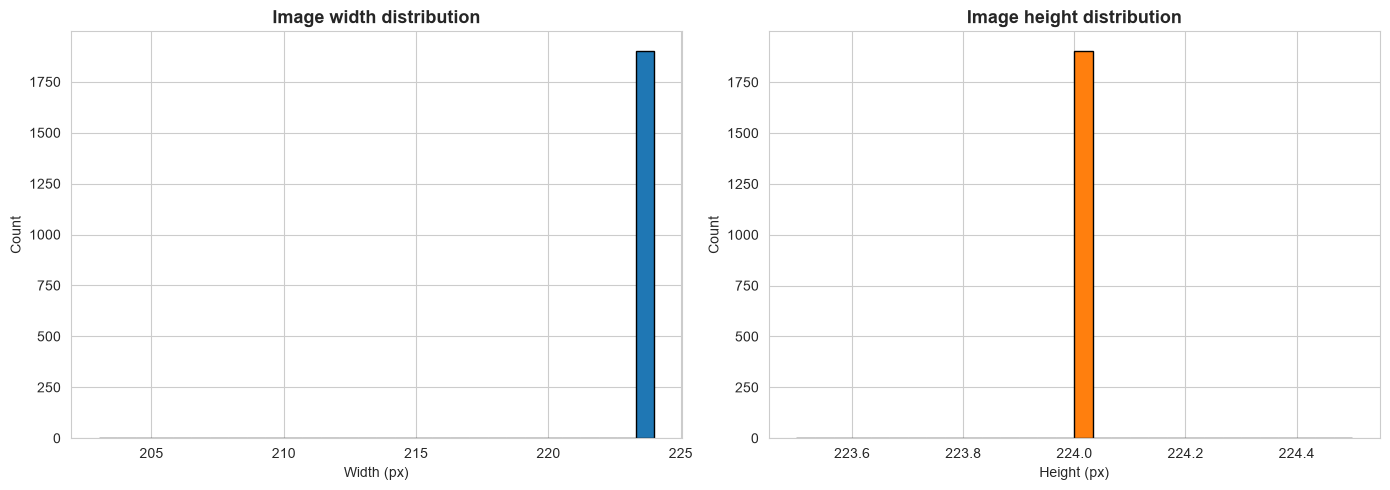

In [ ]:
unique_dims = df.groupby(["width", "height"]).size()
print(f"Unique (width, height) pairs: {len(unique_dims)}")

if len(unique_dims) > 1:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].hist(df["width"],  bins=30, color="#1f77b4", edgecolor="black")
    axes[0].set_title("Image width distribution", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("Width (px)")
    axes[0].set_ylabel("Count")

    axes[1].hist(df["height"], bins=30, color="#ff7f0e", edgecolor="black")
    axes[1].set_title("Image height distribution", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Height (px)")
    axes[1].set_ylabel("Count")

    plt.tight_layout()
    save_fig(FIG_DIR / "04_image_dimensions.png")
    plt.show()
else:
    w, h = list(unique_dims.index)[0]
    print(f"✅ All images are {w}×{h} — no dimension plot needed.")

## Section 3 — Visual & Statistical Data Inspection

We displayed random samples of fractured and normal X-rays to make sure labels looked correct and that train, val, and test sets looked similar to each other. We also checked pixel intensities on 50 images per class — the two classes showed similar brightness, so normalizing with our own dataset mean/std is the right choice. Finally, a five-panel exploratory breakdown (original → resize → grayscale → CLAHE → rotation) illustrated the individual preprocessing operations available — while the actual training pipeline remains `Resize → RandomHorizontalFlip → RandomRotation → ColorJitter → ToTensor → Normalize`, with all hyperparameters driven by `default_train.yaml `.

### 1. Dataset Inspection: Sample Radiographs by Class

⏭️  Skipped (already exists): 05_sample_grid_per_class.png  (set OVERWRITE_FIGS = True or overwrite=True to replace)


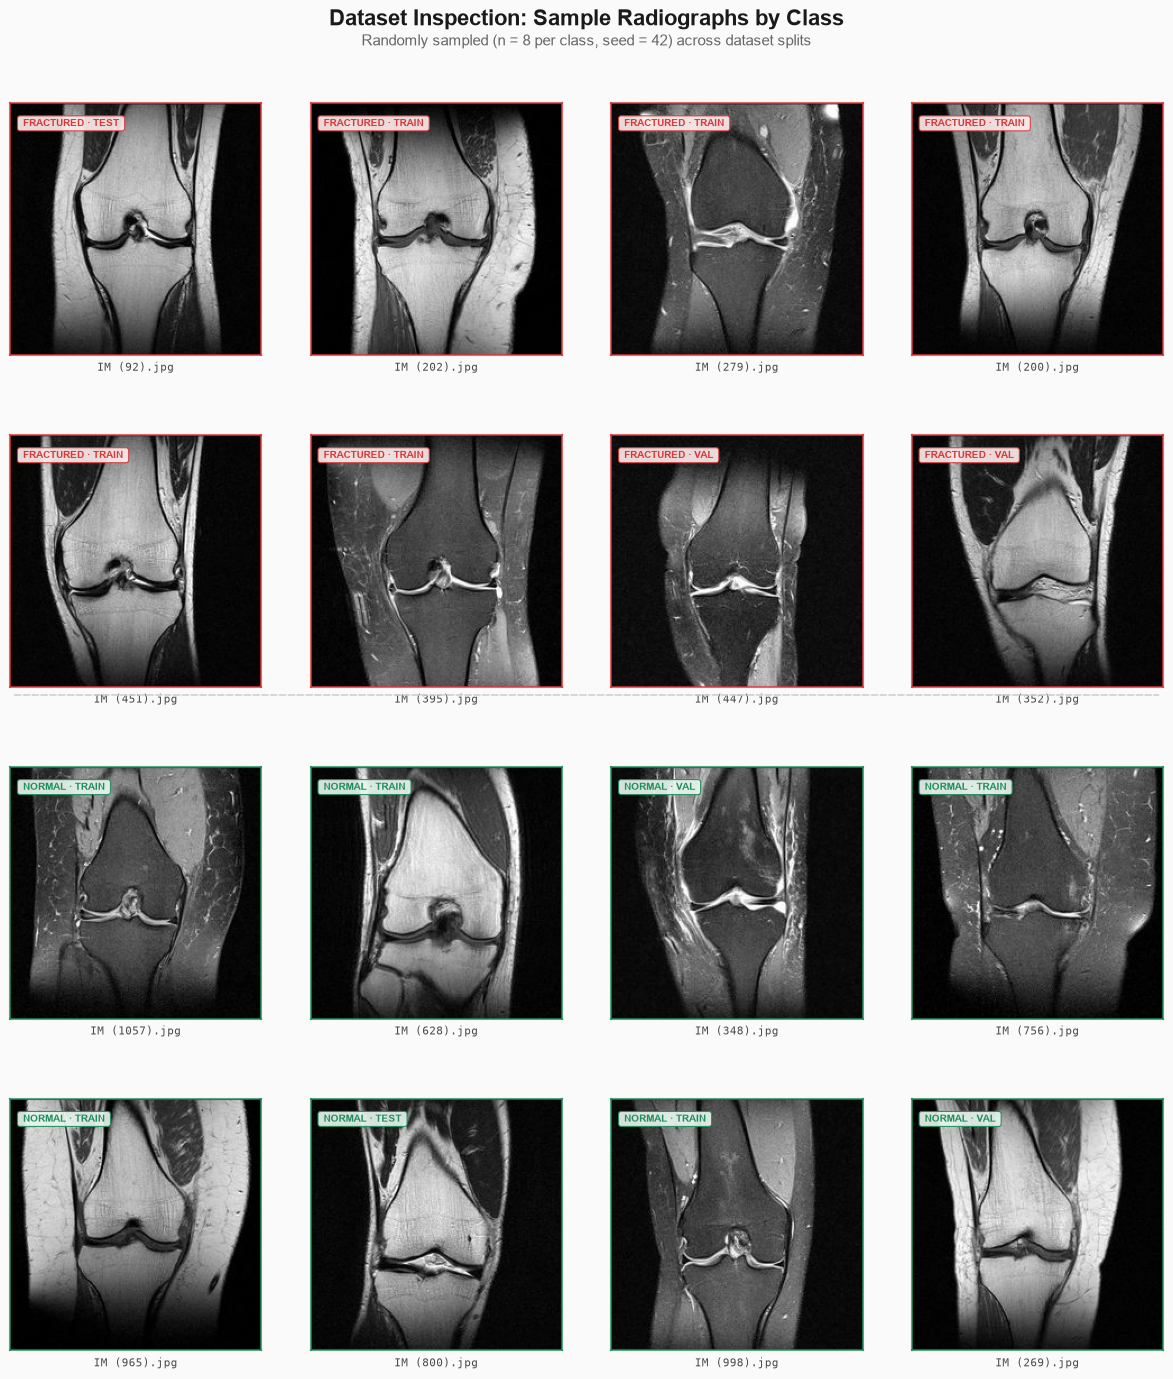

In [84]:
# --- Configuration ---
N_PER_CLASS = 8  # 2 rows of 4 per class (4x4 total)
CLASSES = [
    ("fractured", "Fractured", "#D9383A", "#FDECEC"),  # (key, label, accent, bg)
    ("normal", "Normal", "#1E8E5A", "#E8F5EE"),
]

# --- Figure Setup ---
fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(13, 14.5),
    facecolor="#FAFAFA",
    gridspec_kw={"hspace": 0.32, "wspace": 0.12},
)

# --- Plotting Loop ---
for cls_idx, (cls_key, cls_label, accent_color, badge_bg) in enumerate(CLASSES):
  samples = df[df["class_name"] == cls_key].sample(
      N_PER_CLASS, random_state=42
  )
  row_offset = cls_idx * 2  # Rows 0-1 for first class, 2-3 for second

  for i, (_, row) in enumerate(samples.iterrows()):
    r = row_offset + (i // 4)
    c = i % 4
    ax = axes[r, c]
    ax.set_facecolor("#111111")  # Dark canvas behind X-rays

    try:
      img = load_for_display(row["path"])
      ax.imshow(img, cmap="gray", aspect="equal")
    except Exception as e:
      ax.text(
          0.5,
          0.5,
          f"Load Failed\n{str(e)[:30]}",
          ha="center",
          va="center",
          fontsize=8,
          color="#FF6B6B",
          transform=ax.transAxes,
      )

    # Clean, modern border around each image
    for spine in ax.spines.values():
      spine.set_edgecolor(accent_color)
      spine.set_linewidth(1.5)
      spine.set_alpha(0.75)

    # Remove ticks while keeping the clean frame
    ax.set_xticks([])
    ax.set_yticks([])

    # Top badge: Class + Split pill
    ax.text(
        0.04,
        0.94,
        f" {cls_label.upper()} · {row['split'].upper()} ",
        transform=ax.transAxes,
        fontsize=7.5,
        fontweight="bold",
        color=accent_color,
        va="top",
        ha="left",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor=badge_bg,
            edgecolor=accent_color,
            linewidth=0.8,
            alpha=0.92,
        ),
    )

    # Subtle filename caption below each image
    fname = row["filename"]
    short_name = (fname[:22] + "…") if len(fname) > 23 else fname
    ax.set_xlabel(
        short_name,
        fontsize=8,
        color="#4A4A4A",
        labelpad=5,
        fontfamily="monospace",
    )

# --- Titles & Section Dividers ---
fig.suptitle(
    "Dataset Inspection: Sample Radiographs by Class",
    fontsize=16,
    fontweight="bold",
    color="#1A1A1A",
    y=0.965,
)
fig.text(
    0.5,
    0.94,
    f"Randomly sampled (n = {N_PER_CLASS} per class, seed = 42) across dataset splits",
    ha="center",
    fontsize=10.5,
    color="#666666",
)

# Subtle horizontal divider separating the two classes
line = patches.ConnectionPatch(
    xyA=(0.06, 0.492),
    xyB=(0.94, 0.492),
    coordsA="figure fraction",
    coordsB="figure fraction",
    color="#D0D0D0",
    linewidth=1.2,
    linestyle="--",
)
fig.add_artist(line)

# Adjust margins cleanly (replaces tight_layout which conflicts with fig.text)
fig.subplots_adjust(top=0.90, bottom=0.04, left=0.05, right=0.95)

save_fig(FIG_DIR / "05_sample_grid_per_class.png")
plt.show()


### 2. Dataset Inspection: File-Size & Resolution Outliers

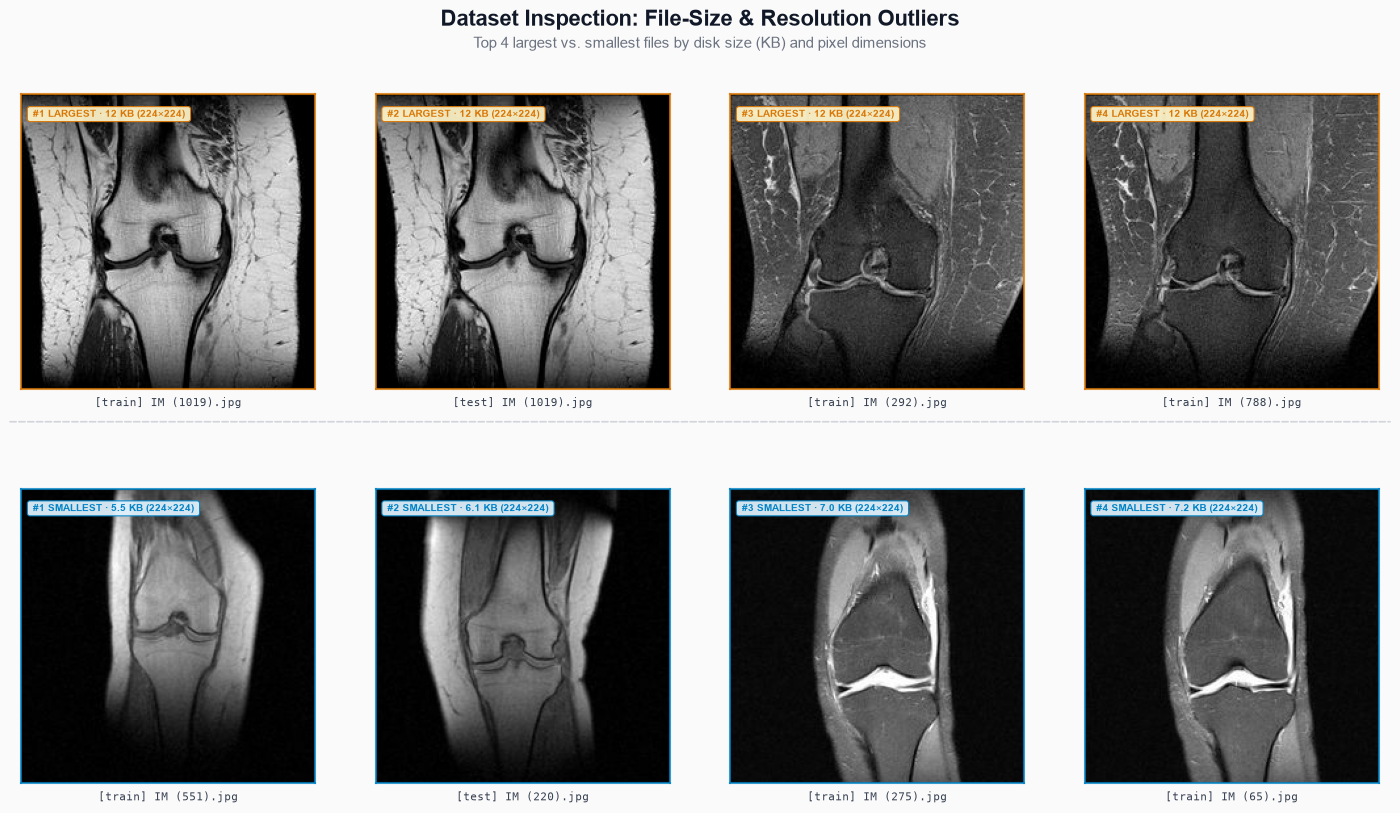

In [87]:
N_OUTLIERS = 4
GROUPS = [
    ("LARGEST", df.nlargest(N_OUTLIERS, "file_size_kb"), "#D97706", "#FEF3C7", "{:.0f} KB"),
    ("SMALLEST", df.nsmallest(N_OUTLIERS, "file_size_kb"), "#0284C7", "#E0F2FE", "{:.1f} KB"),
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=N_OUTLIERS,
    figsize=(15, 8.5),
    facecolor="#FAFAFA",
    gridspec_kw={"hspace": 0.34, "wspace": 0.12},
)

for row_idx, (label, subset, accent_color, badge_bg, size_fmt) in enumerate(GROUPS):
    for col_idx, (_, row) in enumerate(subset.iterrows()):
        ax = axes[row_idx, col_idx]
        ax.set_facecolor("#111111")  # Dark canvas behind radiographs

        try:
            img = load_for_display(row["path"])
            ax.imshow(img, cmap="gray", aspect="equal")
        except Exception as e:
            ax.text(
                0.5, 0.5, f"Load Failed\n{str(e)[:28]}",
                ha="center", va="center", fontsize=8,
                color="#FF6B6B", transform=ax.transAxes
            )

        # Clean color-coded frame
        for spine in ax.spines.values():
            spine.set_edgecolor(accent_color)
            spine.set_linewidth(1.5)
            spine.set_alpha(0.8)

        ax.set_xticks([])
        ax.set_yticks([])

        # Top-left pill badge: Rank + File Size + Resolution
        size_str = size_fmt.format(row["file_size_kb"])
        badge_text = f" #{col_idx + 1} {label} · {size_str} ({row['width']}×{row['height']}) "
        ax.text(
            0.03, 0.95,
            badge_text,
            transform=ax.transAxes,
            fontsize=7.5,
            fontweight="bold",
            color=accent_color,
            va="top",
            ha="left",
            bbox=dict(
                boxstyle="round,pad=0.25",
                facecolor=badge_bg,
                edgecolor=accent_color,
                linewidth=0.8,
                alpha=0.94,
            ),
        )

        # Filename & split caption cleanly positioned below the image
        fname = str(row["filename"])
        short_name = (fname[:25] + "…") if len(fname) > 26 else fname
        split_tag = f"[{row['split']}] " if "split" in row else ""
        ax.set_xlabel(
            f"{split_tag}{short_name}",
            fontsize=8,
            color="#374151",
            labelpad=6,
            fontfamily="monospace",
        )

# --- Titles & Visual Divider ---
fig.suptitle(
    "Dataset Inspection: File-Size & Resolution Outliers",
    fontsize=16,
    fontweight="bold",
    color="#111827",
    y=0.97,
)
fig.text(
    0.5, 0.925,
    f"Top {N_OUTLIERS} largest vs. smallest files by disk size (KB) and pixel dimensions",
    ha="center",
    fontsize=10.5,
    color="#6B7280",
)

# Horizontal dashed divider between Largest (top) and Smallest (bottom)
divider = patches.ConnectionPatch(
    xyA=(0.04, 0.485),
    xyB=(0.96, 0.485),
    coordsA="figure fraction",
    coordsB="figure fraction",
    color="#D1D5DB",
    linewidth=1.2,
    linestyle="--",
)
fig.add_artist(divider)

fig.subplots_adjust(top=0.87, bottom=0.06, left=0.04, right=0.96)
plt.savefig(FIG_DIR / "07_outliers_file_size.png", dpi=150, bbox_inches="tight")
plt.show()


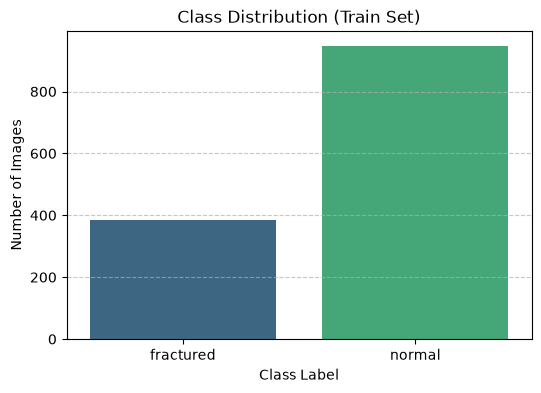

fractured: 386 images (28.9%)
normal: 948 images (71.1%)


In [17]:
# Plotting the balance
plt.figure(figsize=(6, 4))
sns.barplot(x='Class', y='Count', data=df_counts, hue='Class', palette='viridis')
plt.title('Class Distribution (Train Set)')
plt.ylabel('Number of Images')
plt.xlabel('Class Label')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Print percentages
total = df_counts['Count'].sum()
for idx, row in df_counts.iterrows():
    print(f"{row['Class']}: {row['Count']} images ({row['Count']/total:.1%})")


In [32]:
# Sample a small chunk of images to profile resolutions
sample_size = min(100, len(ds))
widths = []
heights = []
modes = [] # RGB, L (Grayscale), etc.

for i in range(len(ds)):
    img, _ = ds[i]
    w, h = img.size
    widths.append(w)
    heights.append(h)
    modes.append(img.mode)

metadata_df = pd.DataFrame({'Width': widths, 'Height': heights, 'Mode': modes})

print("--- Image Resolution Metrics ---")
print(metadata_df[['Width', 'Height']].describe())
print(f"\nUnique image modes found: {Counter(modes)}")


--- Image Resolution Metrics ---
             Width  Height
count  1334.000000  1334.0
mean    223.976012   224.0
std       0.648868     0.0
min     203.000000   224.0
25%     224.000000   224.0
50%     224.000000   224.0
75%     224.000000   224.0
max     224.000000   224.0

Unique image modes found: Counter({'RGB': 1334})


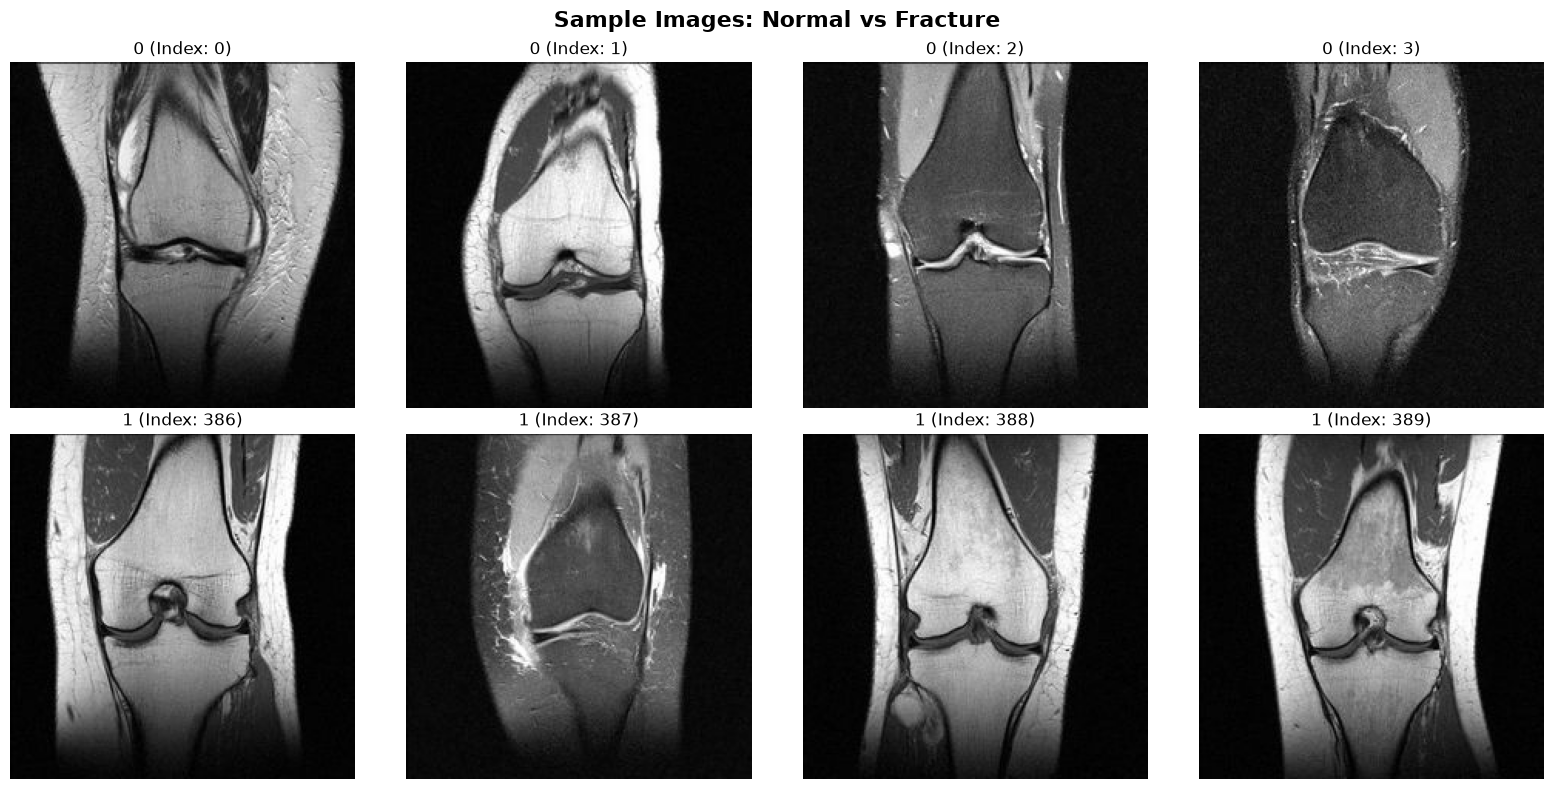

In [37]:
# Group dataset indices by class
class_indices = {cls: [] for cls in ds.classes}
for idx in range(len(ds)):
    _, label = ds[idx]
    class_name = ds.classes[label]
    if len(class_indices[class_name]) < 4:  # Grab up to 4 samples per class
        class_indices[class_name].append(idx)

# Plotting a grid
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Sample Images: Normal vs Fracture', fontsize=16, fontweight='bold')

for row_idx, (class_name, indices) in enumerate(class_indices.items()):
    for col_idx, img_idx in enumerate(indices):
        img, _ = ds[img_idx]
        ax = axes[row_idx, col_idx]
        ax.imshow(img, cmap='gray' if img.mode == 'L' else None)
        ax.set_title(f"{class_name} (Index: {img_idx})")
        ax.axis('off')

plt.tight_layout()
plt.show()


### 3. Pixel Intensity Distribution For 10th sample

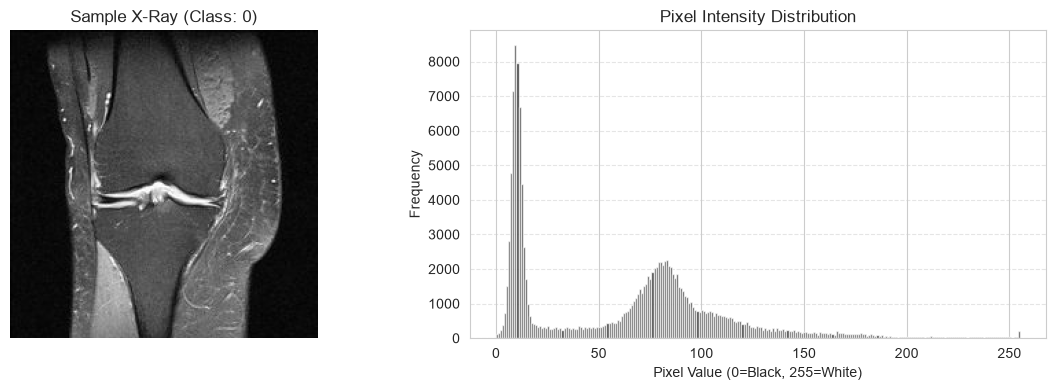

In [ ]:
img, label = ds[10]
img_arr = np.array(img)

plt.figure(figsize=(12, 4))

# Subplot 1: The Raw Image
plt.subplot(1, 2, 1)
plt.imshow(img_arr, cmap='gray')
plt.title(f"Sample X-Ray (Class: {ds.classes[label]})")
plt.axis('off')

# Subplot 2: The Pixel Intensity Histogram
plt.subplot(1, 2, 2)
plt.hist(img_arr.ravel(), bins=256, color='black', alpha=0.7)
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Value (0=Black, 255=White)")
plt.ylabel("Frequency")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 4: Pixel intensity analysis

findfont: Failed to find font weight semibold for Arial, now using 700.


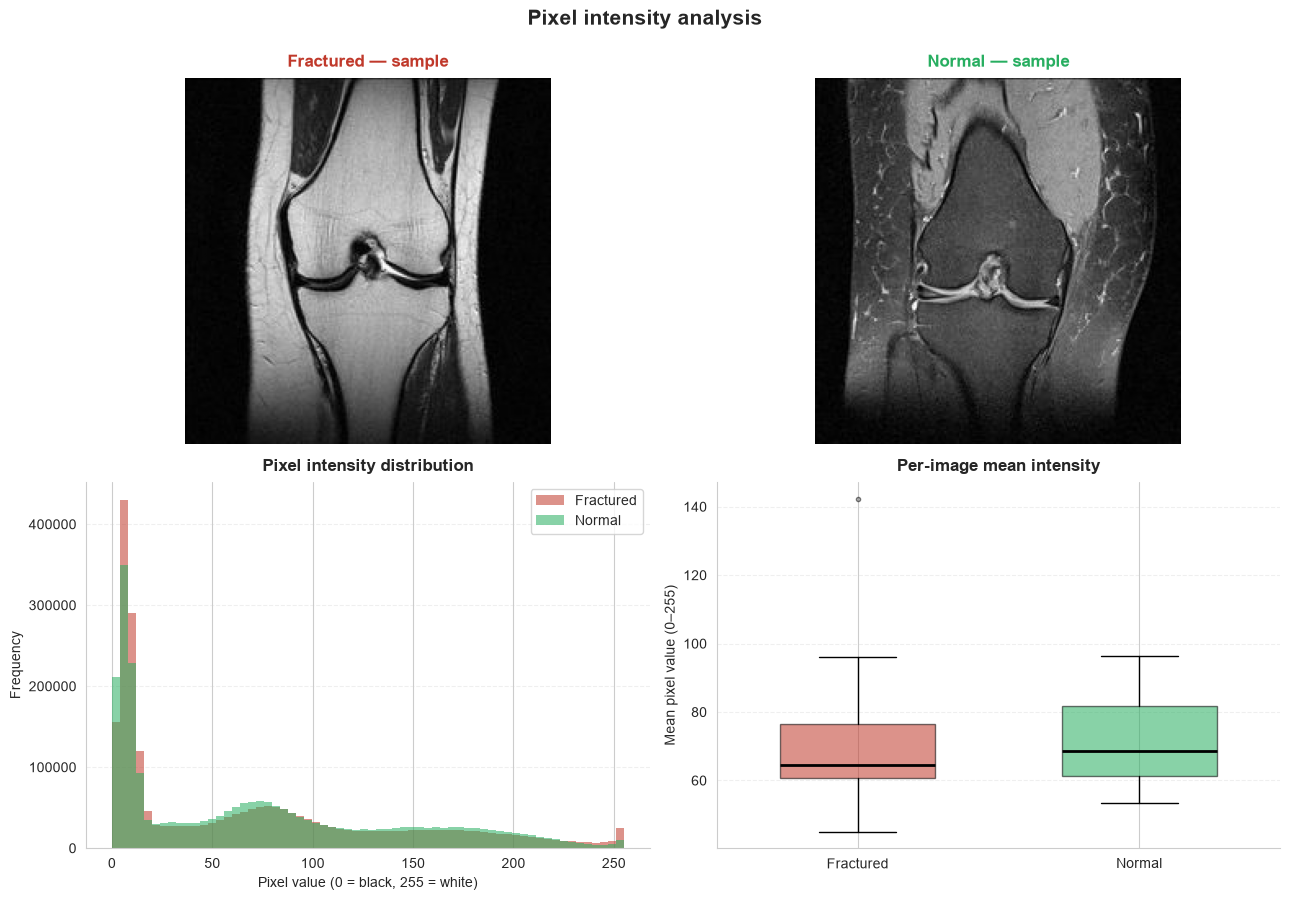

Class          n     mean     std     min     max
────────────────────────────────────────────
fractured     50    68.97   15.40   45.08  142.31
normal        50    72.22   12.28   53.48   96.31


In [ ]:
random.seed(42)

# ── Config ──
N_SAMPLE = 50
COLORS = {"fractured": "#C0392B", "normal": "#27AE60"}
FIGSIZE = (13, 9)
DPI = 150

fig, axes = plt.subplots(2, 2, figsize=FIGSIZE)

# ── (a) Representative samples ──
for ax, cls in zip([axes[0, 0], axes[0, 1]], ["fractured", "normal"]):
    sample = df[df.class_name == cls].sample(1, random_state=42).iloc[0]
    ax.imshow(load_for_display(sample["path"]), cmap="gray")
    ax.set_title(
        f"{cls.capitalize()} — sample",
        fontsize=12, fontweight="semibold", color=COLORS[cls], pad=8,
    )
    ax.axis("off")

# ── (b) Overlaid intensity histograms ──
ax = axes[1, 0]
for cls in ["fractured", "normal"]:
    subset = df[df.class_name == cls].sample(
        n=min(N_SAMPLE, len(df[df.class_name == cls])), random_state=42,
    )
    pixels = []
    for _, row in subset.iterrows():
        try:
            pixels.append(load_for_display(row["path"]).ravel())
        except Exception:
            continue
    ax.hist(
        np.concatenate(pixels), bins=64, range=(0, 255),
        color=COLORS[cls], alpha=0.55, label=cls.capitalize(),
        edgecolor="none",
    )

ax.set_title("Pixel intensity distribution", fontsize=12, fontweight="semibold", pad=8)
ax.set_xlabel("Pixel value (0 = black, 255 = white)", fontsize=10)
ax.set_ylabel("Frequency", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(frameon=True, fontsize=10)
ax.spines[["top", "right"]].set_visible(False)

# ── (c) Per-image mean intensity boxplot ──
ax = axes[1, 1]
data = {}
for cls in ["fractured", "normal"]:
    subset = df[df.class_name == cls].sample(
        n=min(N_SAMPLE, len(df[df.class_name == cls])), random_state=42,
    )
    vals = []
    for _, row in subset.iterrows():
        try:
            vals.append(load_for_display(row["path"]).mean())
        except Exception:
            continue
    data[cls] = vals

bp = ax.boxplot(
    [data["fractured"], data["normal"]],
    tick_labels=["Fractured", "Normal"],
    patch_artist=True, widths=0.55,
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="black", linewidth=1),
    capprops=dict(color="black", linewidth=1),
    flierprops=dict(marker="o", markersize=3, alpha=0.5, markerfacecolor="gray"),
)
for patch, cls in zip(bp["boxes"], ["fractured", "normal"]):
    patch.set_facecolor(COLORS[cls])
    patch.set_alpha(0.55)
    patch.set_edgecolor("black")

ax.set_title("Per-image mean intensity", fontsize=12, fontweight="semibold", pad=8)
ax.set_ylabel("Mean pixel value (0–255)", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.spines[["top", "right"]].set_visible(False)

# ── Layout & save ──
plt.suptitle("Pixel intensity analysis", fontsize=15, fontweight="bold", y=0.995)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_pixel_intensity.png", dpi=DPI, bbox_inches="tight")
plt.show()

# ── Numeric summary ──
print(f"{'Class':<12}{'n':>4}  {'mean':>7}  {'std':>6}  {'min':>6}  {'max':>6}")
print("─" * 44)
for cls, vals in data.items():
    v = np.array(vals)
    print(f"{cls:<12}{len(v):>4}  {v.mean():>7.2f}  {v.std():>6.2f}  {v.min():>6.2f}  {v.max():>6.2f}")

### 5. Five-panel exploratory breakdown

💾 Overwrote: 09_preprocessing_pipeline.png


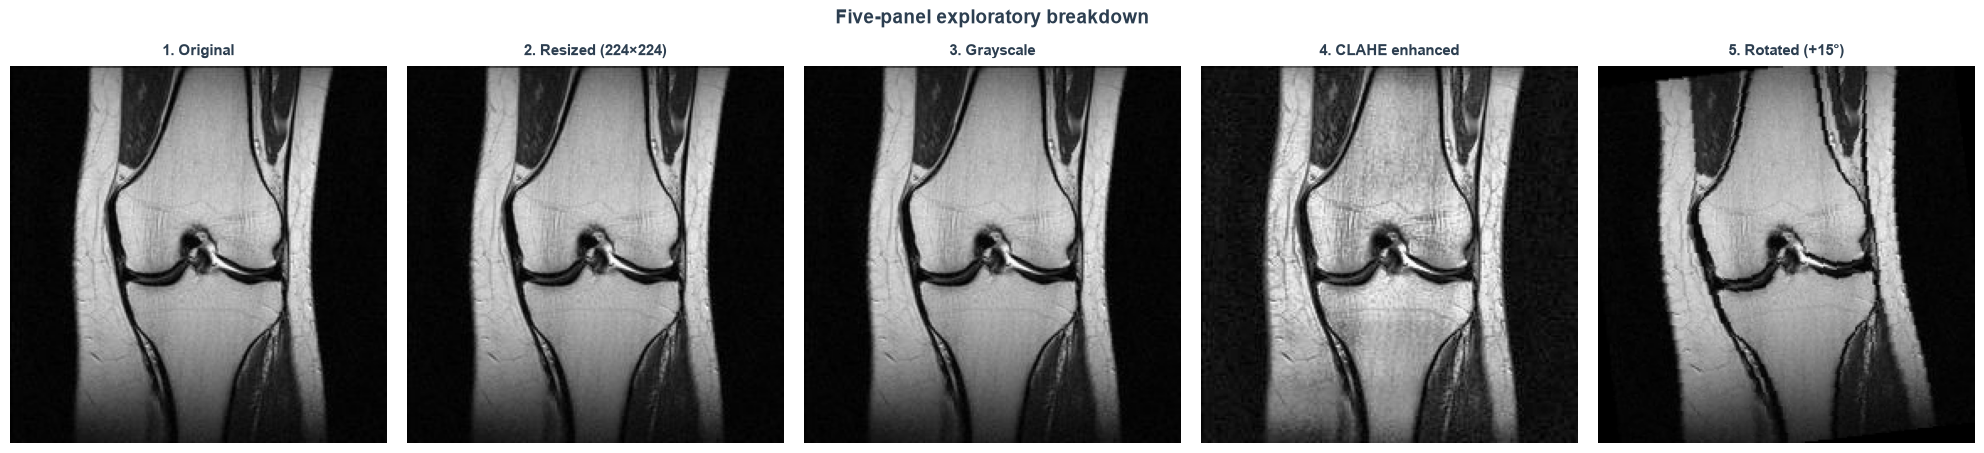

Sample used: IM (92).jpg
Original size: (224, 224)
After resize:  (224, 224)


In [103]:
# ── Config ──
IMG_SIZE = 224
ACCENT = "#2C3E50"      # deep navy for all titles here
DPI = 150

# ── Load one representative sample ──
sample = df[df.class_name == "fractured"].sample(1, random_state=42).iloc[0]
img = Image.open(sample["path"]).convert("RGB")

# ── Individual transforms ──
resize_transform   = transforms.Resize((IMG_SIZE, IMG_SIZE))
grayscale_transform = transforms.Grayscale(num_output_channels=1)
rotation_transform  = transforms.RandomRotation(degrees=15)

# ── CLAHE (works on OpenCV arrays) ──
img_gray_cv = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
img_clahe = clahe.apply(img_gray_cv)

# ── Figure ──
fig, axes = plt.subplots(1, 5, figsize=(20, 4.4))

panels = [
    (img,                                 "1. Original",          None),
    (resize_transform(img),               f"2. Resized ({IMG_SIZE}×{IMG_SIZE})", None),
    (grayscale_transform(img),            "3. Grayscale",         "gray"),
    (img_clahe,                           "4. CLAHE enhanced",    "gray"),
    (rotation_transform(img),             "5. Rotated (+15°)",    None),
]

for ax, (im, title, cmap) in zip(axes, panels):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title, fontsize=11, fontweight="semibold", color=ACCENT, pad=8)
    ax.axis("off")

plt.suptitle("Five-panel exploratory breakdown",
             fontsize=14, fontweight="bold", color=ACCENT, y=1.02)
plt.tight_layout()
save_fig(FIG_DIR / "09_preprocessing_pipeline.png", overwrite=True)
plt.show()

print(f"Sample used: {sample['filename']}")
print(f"Original size: {img.size}")
print(f"After resize:  {resize_transform(img).size}")